# Book Recommender System Using a Medallion Data Lake

**Name:** Pappala Sai Sri Chandana  
**Roll No.:** LCS2023037  

**Objective:** Build an end-to-end **Bronze -> Silver -> Gold** Medallion Data Lake pipeline in Google Colab on the raw **Book-Crossing** dataset (`BX-Users.csv`, `BX-Books.csv`, `BX-Book-Ratings.csv`), and train an **Item-Based Collaborative Filtering** recommender system on the Gold layer.

## Setup & Environment
Import required libraries and create the `bronze/`, `silver/`, and `gold/` data lake directories.

In [2]:
import os
import html
import string
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

for layer in ["raw_data", "bronze", "silver", "gold"]:
    os.makedirs(layer, exist_ok=True)

print("Data lake directories ready:", [d for d in ["bronze", "silver", "gold"] if os.path.isdir(d)])

Data lake directories ready: ['bronze', 'silver', 'gold']


---
## Step 1: Set Up the Data Lake and Build the Bronze Layer
- Download `book-crossings.zip` (skipping if already present) and extract the three CSV files.
- Read the raw CSV files **untouched** using `;` separators and `latin-1` encoding (`escapechar='\\'` for `BX-Books.csv` because raw titles contain backslash-escaped quotes `\"`).
- Add an `ingestion_timestamp` column to each table and write them to `bronze/` as Parquet files.

In [4]:
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_PATH = "book-crossings.zip"
EXPECTED_FILES = ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]

if not all(os.path.exists(os.path.join("raw_data", f)) for f in EXPECTED_FILES):
    if not os.path.exists(ZIP_PATH):
        req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(ZIP_PATH, "wb") as out:
            out.write(resp.read())
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall("raw_data")
    print("Downloaded and extracted raw CSV files.")
else:
    print("Raw CSV files already present in raw_data/.")

# Load untouched raw files
bronze_users = pd.read_csv("raw_data/BX-Users.csv", sep=";", encoding="latin-1", low_memory=False)
bronze_books = pd.read_csv("raw_data/BX-Books.csv", sep=";", encoding="latin-1", escapechar="\\", low_memory=False)
bronze_ratings = pd.read_csv("raw_data/BX-Book-Ratings.csv", sep=";", encoding="latin-1", low_memory=False)

ingestion_ts = pd.Timestamp.utcnow()
for df in (bronze_users, bronze_books, bronze_ratings):
    df["ingestion_timestamp"] = ingestion_ts

bronze_users.to_parquet("bronze/users.parquet", index=False)
bronze_books.to_parquet("bronze/books.parquet", index=False)
bronze_ratings.to_parquet("bronze/ratings.parquet", index=False)

print(f"Saved bronze/users.parquet   -> {bronze_users.shape}")
print(f"Saved bronze/books.parquet   -> {bronze_books.shape}")
print(f"Saved bronze/ratings.parquet -> {bronze_ratings.shape}")

Raw CSV files already present in raw_data/.
Saved bronze/users.parquet   -> (278858, 4)
Saved bronze/books.parquet   -> (271379, 9)
Saved bronze/ratings.parquet -> (1149780, 4)


---
## Step 2: Explore the Bronze Data (EDA)
Read the Bronze Parquet tables back and inspect the five required dimensions. Each check is followed by a one-line summary of what was found and what will be done in Silver.

In [6]:
b_users = pd.read_parquet("bronze/users.parquet")
b_books = pd.read_parquet("bronze/books.parquet")
b_ratings = pd.read_parquet("bronze/ratings.parquet")
print("Loaded Bronze Parquet tables successfully.")

Loaded Bronze Parquet tables successfully.


### 2.1 Shape, Data Types, and Missing-Value Count

In [8]:
for name, df in [("Users", b_users), ("Books", b_books), ("Ratings", b_ratings)]:
    print(f"=== {name}: shape={df.shape} ===")
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_count": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2)
    })
    print(summary.to_string())
    print(f"Exact duplicate rows (excluding timestamp): {df.drop(columns=['ingestion_timestamp']).duplicated().sum()}\n")

=== Users: shape=(278858, 4) ===
                                   dtype  null_count  null_pct
User-ID                            int64           0      0.00
Location                             str           0      0.00
Age                              float64      110762     39.72
ingestion_timestamp  datetime64[us, UTC]           0      0.00
Exact duplicate rows (excluding timestamp): 0

=== Books: shape=(271379, 9) ===
                                   dtype  null_count  null_pct
ISBN                                 str           0       0.0
Book-Title                           str           0       0.0
Book-Author                          str           2       0.0
Year-Of-Publication                int64           0       0.0
Publisher                            str           2       0.0
Image-URL-S                          str           0       0.0
Image-URL-M                          str           0       0.0
Image-URL-L                          str           0       0.0
inges

**Finding & Silver Plan:** `Users` has 278,858 rows with 110,762 missing `Age` values (39.72%), `Books` has 271,379 rows with 2 missing `Book-Author` and 2 missing `Publisher` values, and `Ratings` has 1,149,780 rows with 0 nulls; in Silver we will impute missing `Age` with the median, fill missing author/publisher with `'Unknown'`, and drop unused `Image-URL-*` columns.

### 2.2 Distribution of Ratings (Note How Many Are 0)

              count    pct
Book-Rating               
0            716109  62.28
1              1770   0.15
2              2759   0.24
3              5996   0.52
4              8904   0.77
5             50974   4.43
6             36924   3.21
7             76457   6.65
8            103736   9.02
9             67541   5.87
10            78610   6.84

Zero (implicit) ratings: 716,109 (62.28%)
Explicit ratings (1-10): 433,671 (37.72%)


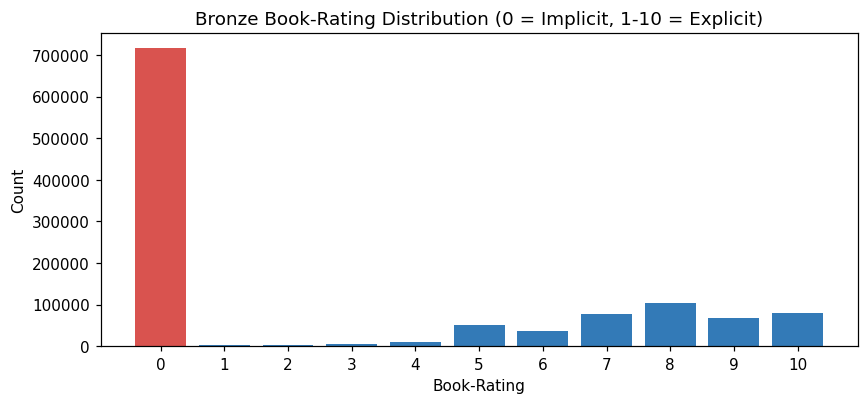

In [11]:
rating_counts = b_ratings["Book-Rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(b_ratings) * 100).round(2)
print(pd.DataFrame({"count": rating_counts, "pct": rating_pct}).to_string())
print(f"\nZero (implicit) ratings: {rating_counts.loc[0]:,} ({rating_pct.loc[0]}%)")
print(f"Explicit ratings (1-10): {rating_counts.loc[1:].sum():,} ({(100 - rating_pct.loc[0]):.2f}%)")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#d9534f" if r == 0 else "#337ab7" for r in rating_counts.index]
ax.bar(rating_counts.index.astype(str), rating_counts.values, color=colors)
ax.set_title("Bronze Book-Rating Distribution (0 = Implicit, 1-10 = Explicit)")
ax.set_xlabel("Book-Rating")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

**Finding & Silver Plan:** Out of 1,149,780 ratings, 716,109 (62.28%) are `0` (implicit/no explicit rating) while 433,671 (37.72%) are explicit ratings from 1 to 10 (peaking at 8); in Silver we will remove all `0` ratings and retain only explicit ratings 1–10.

### 2.3 Distribution of User Ages and Publication Years

User Age -> non-null: 168,096, min: 0.0, max: 244.0, median(5-100): 32.0
  Impossible ages: <5 = 882, >100 = 366, null = 110,762

Publication Year -> min: 0, max: 2050
  Anomalous years: ==0 = 4,619, >2026 = 11, >2005 = 26


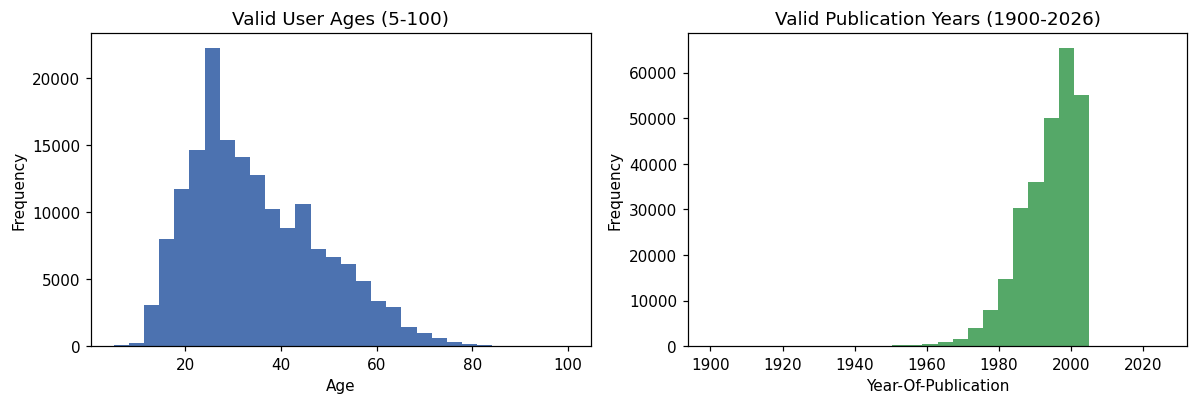

In [14]:
age = b_users["Age"]
year = b_books["Year-Of-Publication"]

print(f"User Age -> non-null: {age.notna().sum():,}, min: {age.min()}, max: {age.max()}, median(5-100): {age[(age>=5)&(age<=100)].median()}")
print(f"  Impossible ages: <5 = {(age < 5).sum():,}, >100 = {(age > 100).sum():,}, null = {age.isna().sum():,}")

current_year = pd.Timestamp.now().year
print(f"\nPublication Year -> min: {year.min()}, max: {year.max()}")
print(f"  Anomalous years: ==0 = {(year == 0).sum():,}, >{current_year} = {(year > current_year).sum():,}, >2005 = {(year > 2005).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
age[(age >= 5) & (age <= 100)].plot(kind="hist", bins=30, ax=axes[0], color="#4c72b0", title="Valid User Ages (5-100)")
axes[0].set_xlabel("Age")
year[(year >= 1900) & (year <= current_year)].plot(kind="hist", bins=30, ax=axes[1], color="#55a868", title=f"Valid Publication Years (1900-{current_year})")
axes[1].set_xlabel("Year-Of-Publication")
plt.tight_layout()
plt.show()

**Finding & Silver Plan:** User ages span 0 to 244 (with 882 values < 5, 366 values > 100, and 110,762 nulls) and publication years span 0 to 2050 (with 4,619 zeros and 11 future years > 2026); in Silver we will set ages `< 5` or `> 100` to null and fill all age nulls with the valid median (32.0), and set publication years equal to `0` or `> current year` to null.

### 2.4 Number of Ratings per User and per Book

       All_Per_User  All_Per_Book  Explicit_Per_User  Explicit_Per_Book
count     105283.00     340556.00           77805.00          185973.00
mean          10.92          3.38               5.57               2.33
std           90.56         12.44              44.00               6.83
min            1.00          1.00               1.00               1.00
50%            1.00          1.00               1.00               1.00
75%            4.00          2.00               3.00               2.00
90%           12.00          6.00               9.00               4.00
95%           29.00         10.00              19.00               6.00
max        13602.00       2502.00            8524.00             707.00

Users with < 10 explicit ratings: 90.57% | Books with < 10 explicit ratings: 96.96%


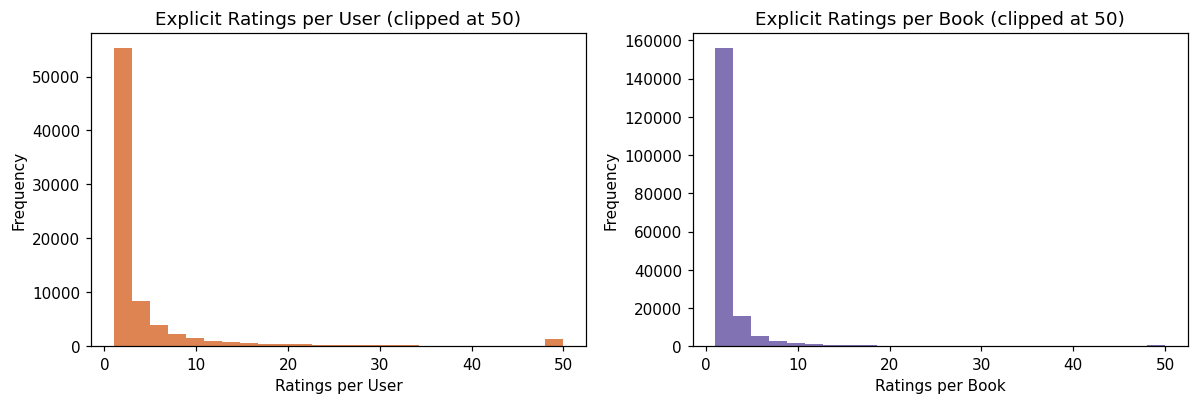

In [17]:
rpu_all = b_ratings.groupby("User-ID").size()
rpb_all = b_ratings.groupby("ISBN").size()

exp_ratings = b_ratings[b_ratings["Book-Rating"] > 0]
rpu_exp = exp_ratings.groupby("User-ID").size()
rpb_exp = exp_ratings.groupby("ISBN").size()

stats_df = pd.DataFrame({
    "All_Per_User": rpu_all.describe(percentiles=[0.5, 0.75, 0.9, 0.95]),
    "All_Per_Book": rpb_all.describe(percentiles=[0.5, 0.75, 0.9, 0.95]),
    "Explicit_Per_User": rpu_exp.describe(percentiles=[0.5, 0.75, 0.9, 0.95]),
    "Explicit_Per_Book": rpb_exp.describe(percentiles=[0.5, 0.75, 0.9, 0.95]),
}).round(2)
print(stats_df.to_string())
print(f"\nUsers with < 10 explicit ratings: {(rpu_exp < 10).mean()*100:.2f}% | Books with < 10 explicit ratings: {(rpb_exp < 10).mean()*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rpu_exp.clip(upper=50).plot(kind="hist", bins=25, ax=axes[0], color="#dd8452", title="Explicit Ratings per User (clipped at 50)")
axes[0].set_xlabel("Ratings per User")
rpb_exp.clip(upper=50).plot(kind="hist", bins=25, ax=axes[1], color="#8172b3", title="Explicit Ratings per Book (clipped at 50)")
axes[1].set_xlabel("Ratings per Book")
plt.tight_layout()
plt.show()

**Finding & Silver Plan:** The median user and median book each have only 1 rating (90.57% of explicit-rating users and 96.96% of explicit-rating books have fewer than 10 ratings); in Silver we will filter to users and books with at least 10 explicit ratings (iteratively until convergence) so item-item cosine similarities are statistically meaningful.

### 2.5 Matrix Sparsity

In [20]:
n_users = b_users["User-ID"].nunique()
n_books = b_books["ISBN"].nunique()
total_possible = n_users * n_books
actual_all = len(b_ratings)
actual_valid = (b_ratings["User-ID"].isin(b_users["User-ID"]) & b_ratings["ISBN"].isin(b_books["ISBN"])).sum()

density_pct = actual_all / total_possible * 100
sparsity_pct = 100.0 - density_pct

print(f"Users table unique User-IDs : {n_users:,}")
print(f"Books table unique ISBNs    : {n_books:,}")
print(f"Total possible pairs        : {total_possible:,}")
print(f"Actual ratings (all)        : {actual_all:,} (valid in both tables: {actual_valid:,})")
print(f"Matrix density              : {density_pct:.6f}%")
print(f"Matrix sparsity             : {sparsity_pct:.6f}%")

Users table unique User-IDs : 278,858
Books table unique ISBNs    : 271,379
Total possible pairs        : 75,676,205,182
Actual ratings (all)        : 1,149,780 (valid in both tables: 1,031,175)
Matrix density              : 0.001519%
Matrix sparsity             : 99.998481%


**Finding & Silver Plan:** Only 0.001519% of the ~75.68 billion possible user-book pairs have a rating (99.998481% sparse, and 118,605 ratings reference ISBNs missing from `Books`); in Silver we will enforce referential integrity and apply the >= 10 rating threshold, then store the Gold rating matrix as a `scipy.sparse.csr_matrix`.

---
## Step 3: Clean the Data and Build the Silver Layer

**Minimum-Rating Threshold Choice & Justification (`min_ratings = 10`):**
From Step 2 EDA, 90.57% of users and 96.96% of books with explicit ratings have fewer than 10 ratings (median = 1), driving raw matrix density down to `0.001519%`. Choosing a threshold of **10 explicit ratings** (applied iteratively to both users and books until convergence) removes cold-start noise where cosine similarity over 1–2 co-ratings produces spurious 1.0 matches, while retaining an active core of **1,820 users, 2,030 books, and 41,469 ratings** (raising matrix density >700x to **1.12%**).

In [23]:
s_users = pd.read_parquet("bronze/users.parquet").drop(columns=["ingestion_timestamp"])
s_books = pd.read_parquet("bronze/books.parquet").drop(columns=["ingestion_timestamp"])
s_ratings = pd.read_parquet("bronze/ratings.parquet").drop(columns=["ingestion_timestamp"])

# 1. Clean text columns & drop image URLs
def clean_text(val, title_case=True):
    if pd.isna(val):
        return "Unknown"
    txt = " ".join(html.unescape(str(val)).split())
    if not txt:
        return "Unknown"
    return string.capwords(txt) if title_case else txt

s_books = s_books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
s_books["ISBN"] = s_books["ISBN"].astype(str).str.strip().str.upper()
s_books["Book-Title"] = s_books["Book-Title"].apply(clean_text)
s_books["Book-Author"] = s_books["Book-Author"].apply(clean_text)
s_books["Publisher"] = s_books["Publisher"].apply(clean_text)

# 2. Fix publication years: set 0 or future years to null
current_year = pd.Timestamp.now().year
s_books["Year-Of-Publication"] = (
    s_books["Year-Of-Publication"]
    .where((s_books["Year-Of-Publication"] > 0) & (s_books["Year-Of-Publication"] <= current_year), pd.NA)
    .astype("Int64")
)

# 3. Fix user ages: < 5 or > 100 -> null, then fill nulls with median age
s_users.loc[(s_users["Age"] < 5) | (s_users["Age"] > 100), "Age"] = np.nan
median_age = s_users["Age"].median()
s_users["Age"] = s_users["Age"].fillna(median_age)

# 4. Split Location into city, state, country (cleaned & standardized)
loc_split = s_users["Location"].fillna("").astype(str).str.split(",")
s_users["city"] = loc_split.apply(lambda p: clean_text(p[0]) if len(p) >= 1 and p[0].strip() else "Unknown")
s_users["state"] = loc_split.apply(lambda p: clean_text(p[1]) if len(p) >= 2 and p[1].strip() else "Unknown")
s_users["country"] = loc_split.apply(lambda p: clean_text(p[-1]) if len(p) >= 3 and p[-1].strip() else "Unknown")
s_users = s_users.drop(columns=["Location"])

# 5. Remove duplicate rows across all three tables
s_users = s_users.drop_duplicates().drop_duplicates(subset=["User-ID"])
s_books = s_books.drop_duplicates().drop_duplicates(subset=["ISBN"])

s_ratings["ISBN"] = s_ratings["ISBN"].astype(str).str.strip().str.upper()
s_ratings = s_ratings.drop_duplicates().drop_duplicates(subset=["User-ID", "ISBN"])

# 6. Remove ratings of 0 and keep explicit ratings 1..10
s_ratings = s_ratings[(s_ratings["Book-Rating"] >= 1) & (s_ratings["Book-Rating"] <= 10)]

# 7. Referential integrity: keep only ratings whose User-ID and ISBN exist in users and books
s_ratings = s_ratings[
    s_ratings["User-ID"].isin(s_users["User-ID"]) & s_ratings["ISBN"].isin(s_books["ISBN"])
]

# 8. Keep only users and books with >= MIN_RATINGS explicit ratings (iterative convergence)
MIN_RATINGS = 10
while True:
    prev_len = len(s_ratings)
    u_counts = s_ratings["User-ID"].value_counts()
    b_counts = s_ratings["ISBN"].value_counts()
    s_ratings = s_ratings[
        s_ratings["User-ID"].isin(u_counts[u_counts >= MIN_RATINGS].index)
        & s_ratings["ISBN"].isin(b_counts[b_counts >= MIN_RATINGS].index)
    ]
    if len(s_ratings) == prev_len:
        break

s_users = s_users[s_users["User-ID"].isin(s_ratings["User-ID"])].reset_index(drop=True)
s_books = s_books[s_books["ISBN"].isin(s_ratings["ISBN"])].reset_index(drop=True)
s_ratings = s_ratings.reset_index(drop=True)

s_users.to_parquet("silver/users.parquet", index=False)
s_books.to_parquet("silver/books.parquet", index=False)
s_ratings.to_parquet("silver/ratings.parquet", index=False)

silver_density = len(s_ratings) / (len(s_users) * len(s_books)) * 100
print(f"Silver users   : {s_users.shape} (median age imputed: {median_age})")
print(f"Silver books   : {s_books.shape} (null years: {s_books['Year-Of-Publication'].isna().sum()})")
print(f"Silver ratings : {s_ratings.shape} | density: {silver_density:.2f}%")
print(f"Min ratings per user: {s_ratings['User-ID'].value_counts().min()} | Min ratings per book: {s_ratings['ISBN'].value_counts().min()}")

Silver users   : (1820, 5) (median age imputed: 32.0)
Silver books   : (2030, 5) (null years: 4)
Silver ratings : (41469, 3) | density: 1.12%
Min ratings per user: 10 | Min ratings per book: 10


---
## Step 4: Build the Gold Layer
From the Silver tables, build and save to `gold/`:
1. A sparse **user-book rating matrix** (`gold/user_book_matrix.npz`) with row/column index mappings (`gold/user_index.parquet`, `gold/book_index.parquet`).
2. A **book lookup table** (`gold/book_lookup.parquet`) with `book_id`, `title`, and `author`.
3. **User-level** (`gold/user_aggregates.parquet`) and **book-level** (`gold/book_aggregates.parquet`) aggregates (`rating_count`, `avg_rating`).

In [25]:
g_users = pd.read_parquet("silver/users.parquet")
g_books = pd.read_parquet("silver/books.parquet")
g_ratings = pd.read_parquet("silver/ratings.parquet")

# 1. Sparse user-book rating matrix (rows = users, cols = books)
user_ids = np.sort(g_ratings["User-ID"].unique())
book_ids = np.sort(g_ratings["ISBN"].unique())

user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
book_to_idx = {bid: i for i, bid in enumerate(book_ids)}

row_idx = g_ratings["User-ID"].map(user_to_idx).to_numpy()
col_idx = g_ratings["ISBN"].map(book_to_idx).to_numpy()
rating_vals = g_ratings["Book-Rating"].to_numpy(dtype=np.float32)

user_book_matrix = csr_matrix((rating_vals, (row_idx, col_idx)), shape=(len(user_ids), len(book_ids)))
save_npz("gold/user_book_matrix.npz", user_book_matrix)

pd.DataFrame({"matrix_row": np.arange(len(user_ids)), "User-ID": user_ids}).to_parquet("gold/user_index.parquet", index=False)
pd.DataFrame({"matrix_col": np.arange(len(book_ids)), "book_id": book_ids}).to_parquet("gold/book_index.parquet", index=False)

# 2. Book lookup table
book_lookup = (
    g_books.rename(columns={
        "ISBN": "book_id",
        "Book-Title": "title",
        "Book-Author": "author",
        "Year-Of-Publication": "year_of_publication",
        "Publisher": "publisher"
    })[["book_id", "title", "author", "year_of_publication", "publisher"]]
    .set_index("book_id")
    .loc[book_ids]
    .reset_index()
)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# 3. User-level and book-level aggregates
user_aggregates = (
    g_ratings.groupby("User-ID")["Book-Rating"]
    .agg(rating_count="count", avg_rating="mean")
    .reset_index()
)
user_aggregates["avg_rating"] = user_aggregates["avg_rating"].round(3)
user_aggregates.to_parquet("gold/user_aggregates.parquet", index=False)

book_aggregates = (
    g_ratings.groupby("ISBN")["Book-Rating"]
    .agg(rating_count="count", avg_rating="mean")
    .reset_index()
    .rename(columns={"ISBN": "book_id"})
    .merge(book_lookup[["book_id", "title", "author"]], on="book_id", how="left")
    [["book_id", "title", "author", "rating_count", "avg_rating"]]
)
book_aggregates["avg_rating"] = book_aggregates["avg_rating"].round(3)
book_aggregates.to_parquet("gold/book_aggregates.parquet", index=False)

print("Gold user-book matrix shape:", user_book_matrix.shape, "| stored non-zeros:", user_book_matrix.nnz)
print("Top 5 most-rated books in Gold:")
print(book_aggregates.sort_values("rating_count", ascending=False).head(5).to_string(index=False))

Gold user-book matrix shape: (1820, 2030) | stored non-zeros: 41469
Top 5 most-rated books in Gold:
   book_id                                                            title        author  rating_count  avg_rating
0316666343                                        The Lovely Bones: A Novel  Alice Sebold           223       8.238
0385504209                                                The Da Vinci Code     Dan Brown           177       8.610
0312195516                              The Red Tent (bestselling Backlist) Anita Diamant           132       8.492
0142001740                                          The Secret Life Of Bees Sue Monk Kidd           125       8.664
059035342X Harry Potter And The Sorcerer's Stone (harry Potter (paperback)) J. K. Rowling           119       9.042


---
## Step 5: Build the Recommender (Item-Based Collaborative Filtering)
1. Load the sparse rating matrix from `gold/` and transpose it so **each row is a book and each column is a user**.
2. Fit `NearestNeighbors(metric="cosine", algorithm="brute")` on the sparse book-user matrix.
3. Implement `similar_books(book_title, n=10)` to return the 10 most similar books.
4. Implement `recommend(user_id, n=10)` to weight candidate neighbor similarities by the user's high ratings, exclude books the user already read, and return the top `n` titles.

In [27]:
import re

# 1. Load Gold matrix & lookup tables
gold_user_book = load_npz("gold/user_book_matrix.npz")
book_user_matrix = gold_user_book.T.tocsr()  # rows = books, cols = users

user_index_df = pd.read_parquet("gold/user_index.parquet")
book_index_df = pd.read_parquet("gold/book_index.parquet")
book_lookup_df = pd.read_parquet("gold/book_lookup.parquet").set_index("book_id")

idx_to_book = book_index_df["book_id"].to_numpy()
book_to_idx = {bid: int(i) for i, bid in enumerate(idx_to_book)}
user_to_idx = {int(uid): int(r) for r, uid in zip(user_index_df["matrix_row"], user_index_df["User-ID"])}

def base_title_key(title):
    """Normalize edition/subtitle suffixes so duplicate editions of the same work collapse."""
    t = re.sub(r"\s*\(.*$", "", str(title).lower()).strip()
    t = re.sub(r"\s*:\s*a novel\s*$", "", t).strip()
    return t

# 2. Compute cosine similarity using NearestNeighbors
nn_model = NearestNeighbors(metric="cosine", algorithm="brute")
nn_model.fit(book_user_matrix)

print("Book-User matrix shape:", book_user_matrix.shape)

# 3. Similar books function
def similar_books(book_title, n=10):
    """Return the top n books most similar to book_title using cosine similarity."""
    exact = book_lookup_df[book_lookup_df["title"].str.lower() == book_title.strip().lower()]
    matches = exact if len(exact) > 0 else book_lookup_df[
        book_lookup_df["title"].str.contains(book_title.strip(), case=False, regex=False, na=False)
    ]
    if len(matches) == 0:
        raise ValueError(f"No book found matching title: {book_title!r}")

    query_isbn = matches.index[0]
    query_title = book_lookup_df.loc[query_isbn, "title"]
    query_idx = book_to_idx[query_isbn]

    fetch_k = min(n * 5 + 1, book_user_matrix.shape[0])
    distances, indices = nn_model.kneighbors(book_user_matrix.getrow(query_idx), n_neighbors=fetch_k)

    results = []
    seen_titles = {base_title_key(query_title)}
    for dist, b_idx in zip(distances[0][1:], indices[0][1:]):
        sim = 1.0 - float(dist)
        cand_isbn = idx_to_book[b_idx]
        cand_title = book_lookup_df.loc[cand_isbn, "title"]
        t_key = base_title_key(cand_title)
        if t_key in seen_titles:
            continue
        seen_titles.add(t_key)
        results.append({
            "book_id": cand_isbn,
            "title": cand_title,
            "author": book_lookup_df.loc[cand_isbn, "author"],
            "cosine_similarity": round(sim, 4)
        })
        if len(results) >= n:
            break

    print(f"Query Book: {query_title} ({query_isbn})")
    return pd.DataFrame(results)

# Quick test of similar_books()
print(similar_books("The Da Vinci Code", n=10).to_string(index=False))

Book-User matrix shape: (2030, 1820)
Query Book: The Da Vinci Code (0385504209)
   book_id                     title             author  cosine_similarity
0671027360           Angels & Demons          Dan Brown             0.2398
0316666343 The Lovely Bones: A Novel       Alice Sebold             0.1783
0316155306      The Narrows: A Novel   Michael Connelly             0.1763
0374199698        Middlesex: A Novel  Jeffrey Eugenides             0.1749
0316780812        Sea Glass: A Novel       Anita Shreve             0.1616
0525947299          No Second Chance       Harlan Coben             0.1599
0553802488                  The Face        Dean Koontz             0.1575
0446531332        Nights In Rodanthe    Nicholas Sparks             0.1560
0142001740   The Secret Life Of Bees      Sue Monk Kidd             0.1556
0345452577       The Conspiracy Club Jonathan Kellerman             0.1506


In [28]:
# 4. User recommendation function
def recommend(user_id, n=10, high_rating_threshold=8, neighbors_per_book=25):
    """Recommend top n unread books for user_id via rating-weighted item cosine similarity."""
    if user_id not in user_to_idx:
        raise ValueError(f"User-ID {user_id} not found in Gold rating matrix.")

    u_row = gold_user_book.getrow(user_to_idx[user_id])
    rated_b_indices = u_row.indices
    rated_scores = u_row.data

    read_isbns = {idx_to_book[i] for i in rated_b_indices}
    read_titles = {base_title_key(book_lookup_df.loc[isbn, "title"]) for isbn in read_isbns}

    # Books the user rated highly (fallback to >= user median if none >= threshold)
    liked_mask = rated_scores >= high_rating_threshold
    if not liked_mask.any():
        liked_mask = rated_scores >= np.median(rated_scores)

    liked_indices = rated_b_indices[liked_mask]
    liked_ratings = rated_scores[liked_mask]

    candidate_scores = {}
    for b_idx, user_rating in zip(liked_indices, liked_ratings):
        k = min(neighbors_per_book + 1, book_user_matrix.shape[0])
        distances, indices = nn_model.kneighbors(book_user_matrix.getrow(b_idx), n_neighbors=k)
        for dist, nbr_idx in zip(distances[0][1:], indices[0][1:]):
            sim = 1.0 - float(dist)
            if sim <= 0:
                continue
            cand_isbn = idx_to_book[nbr_idx]
            cand_title = book_lookup_df.loc[cand_isbn, "title"]
            if cand_isbn in read_isbns or base_title_key(cand_title) in read_titles:
                continue
            candidate_scores[cand_isbn] = candidate_scores.get(cand_isbn, 0.0) + sim * float(user_rating)

    # Keep highest-scoring edition per unique book work
    best_by_title = {}
    for cand_isbn, score in candidate_scores.items():
        t_key = base_title_key(book_lookup_df.loc[cand_isbn, "title"])
        if t_key not in best_by_title or score > best_by_title[t_key][1]:
            best_by_title[t_key] = (cand_isbn, score)

    ranked = sorted(best_by_title.values(), key=lambda x: x[1], reverse=True)[:n]
    recs = [
        {
            "book_id": isbn,
            "title": book_lookup_df.loc[isbn, "title"],
            "author": book_lookup_df.loc[isbn, "author"],
            "weighted_score": round(score, 3),
        }
        for isbn, score in ranked
    ]
    return pd.DataFrame(recs)

print("recommend(user_id, n=10) function is ready.")

recommend(user_id, n=10) function is ready.


---
## Step 6: Demo and Sanity Check
Run `recommend()` for three distinct users (`254`, `638`, `2033`) and display each user's highly rated books side-by-side with their top-10 recommendations.

In [30]:
demo_users = [254, 638, 2033]

for uid in demo_users:
    u_row = gold_user_book.getrow(user_to_idx[uid])
    liked_df = pd.DataFrame({
        "book_id": [idx_to_book[i] for i in u_row.indices],
        "rating": u_row.data.astype(int),
    })
    liked_df = (
        liked_df.merge(book_lookup_df.reset_index()[["book_id", "title", "author"]], on="book_id")
        .sort_values(["rating", "title"], ascending=[False, True])
        .head(10)
        .reset_index(drop=True)
    )
    recs_df = recommend(uid, n=10).reset_index(drop=True)

    # Display side-by-side
    side_by_side = pd.DataFrame({
        "Liked_Title": liked_df["title"].str.slice(0, 42),
        "User_Rating": liked_df["rating"],
        "Recommended_Title": recs_df["title"].str.slice(0, 42),
        "Rec_Author": recs_df["author"].str.slice(0, 22),
        "Score": recs_df["weighted_score"],
    })
    print("=" * 125)
    print(f"USER {uid} | Highly Rated Books (Left) vs. Top 10 Recommendations (Right)")
    print("=" * 125)
    print(side_by_side.to_string(index=True))
    print()

USER 254 | Highly Rated Books (Left) vs. Top 10 Recommendations (Right)
                                  Liked_Title  User_Rating                           Recommended_Title          Rec_Author   Score
0                               American Gods           10  Harry Potter And The Order Of The Phoenix        J. K. Rowling  19.169
1                                        1984            9  The Return Of The King (the Lord Of The Ri    J. R. R. Tolkien  13.099
2                      American Gods: A Novel            9                                    Stardust         Neil Gaiman   8.458
3  Harry Potter And The Chamber Of Secrets (b            9  The Two Towers (the Lord Of The Rings, Par    J. R. R. Tolkien   7.577
4  Harry Potter And The Chamber Of Secrets (b            9  The Amber Spyglass (his Dark Materials, Bo      Philip Pullman   6.925
5  Harry Potter And The Goblet Of Fire (book             9                      The Catcher In The Rye       J.d. Salinger   5.590
6  Harry Po